# Data Preprocessing

## 1-Load the Heart Disease UCI dataset into a Pandas DataFrame.

In [13]:
import pandas as pd
from ucimlrepo import fetch_ucirepo 
pd.set_option('display.max_columns', None)
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 

### 1 for heart disease 
### 0 for no heart disease

y = (y > 0).astype(int)  

# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 

X.to_csv("D:\\Heart_Disease_Project\\data\\heart_disease_features_Raw.csv", index=False)
y.to_csv("D:\\Heart_Disease_Project\\data\\heart_disease_target_Raw.csv", index=False)

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

## 2-  Handle missing values (imputation or removal). 
### Checking the missing values

In [7]:
print(X.info())
print(X[X.isnull().any(axis=1)])
print()
print(X['ca'].value_counts())
print()
print(X['thal'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB
None
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
87    53    0   3       128   216    0        2      115      0      0.0   
166   52    1   3       138   223    0        0      169      0      0.0   
192   43    1   4       1

### I will use imputation approach using iterative imputer as:

- Handles multivariate relationships by modeling each feature with missing values as a function of others.

- Provides more accurate imputations compared to simple methods (mean/mode), especially for correlated medical data.

- Suitable for your small dataset (303 rows) without heavy computational cost.

- Helps preserve the underlying data distribution and patterns.

In [178]:
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer

imp = IterativeImputer(random_state=0)


X_imputed = imp.fit_transform(X)


X_filled = pd.DataFrame(X_imputed, columns=X.columns)

# 'ca' or 'thal' are categorical integers, round them to integers
X_filled['ca'] = X_filled['ca'].round().astype(int)
X_filled['thal'] = X_filled['thal'].round().astype(int)

## 3. Perform data encoding (one-hot encoding for categorical variables).
### I used drop_first so that:
to avoid multicollinearity and ensure that the encoded features are linearly independent by dropping the first category in one-hot encoding.

In [179]:
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

# One Hot encoding
X_encoded = pd.get_dummies(X_filled, columns=categorical_cols, drop_first=True)


## 4. Standardize numerical features using MinMaxScaler or StandardScaler. 

### I used StandardScaler as:
StandardScaler is less affected by outliers and preserves the distribution of the data around zero, making it suitable for models that assume normally distributed features.

In [180]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

# Scaling
scaler = StandardScaler()
X_encoded[numerical_cols] = scaler.fit_transform(X_encoded[numerical_cols])
print(X_encoded.head())

        age  trestbps      chol   thalach   oldpeak        ca  sex_1.0  \
0  0.948726  0.757525 -0.264900  0.017197  1.087338 -0.719117     True   
1  1.392002  1.611220  0.760415 -1.821905  0.397182  2.500969     True   
2  1.392002 -0.665300 -0.342283 -0.902354  1.346147  1.427607     True   
3 -1.932564 -0.096170  0.063974  1.637359  2.122573 -0.719117     True   
4 -1.489288 -0.096170 -0.825922  0.980537  0.310912 -0.719117    False   

   cp_2.0  cp_3.0  cp_4.0  fbs_1.0  restecg_1.0  restecg_2.0  exang_1.0  \
0   False   False   False     True        False         True      False   
1   False   False    True    False        False         True       True   
2   False   False    True    False        False         True       True   
3   False    True   False    False        False        False      False   
4    True   False   False    False        False         True      False   

   slope_2.0  slope_3.0  thal_6  thal_7  
0      False       True    True   False  
1       True      Fa

## 5. Conduct Exploratory Data Analysis (EDA) with histograms, correlation heatmap, and boxplots.

### Histograms

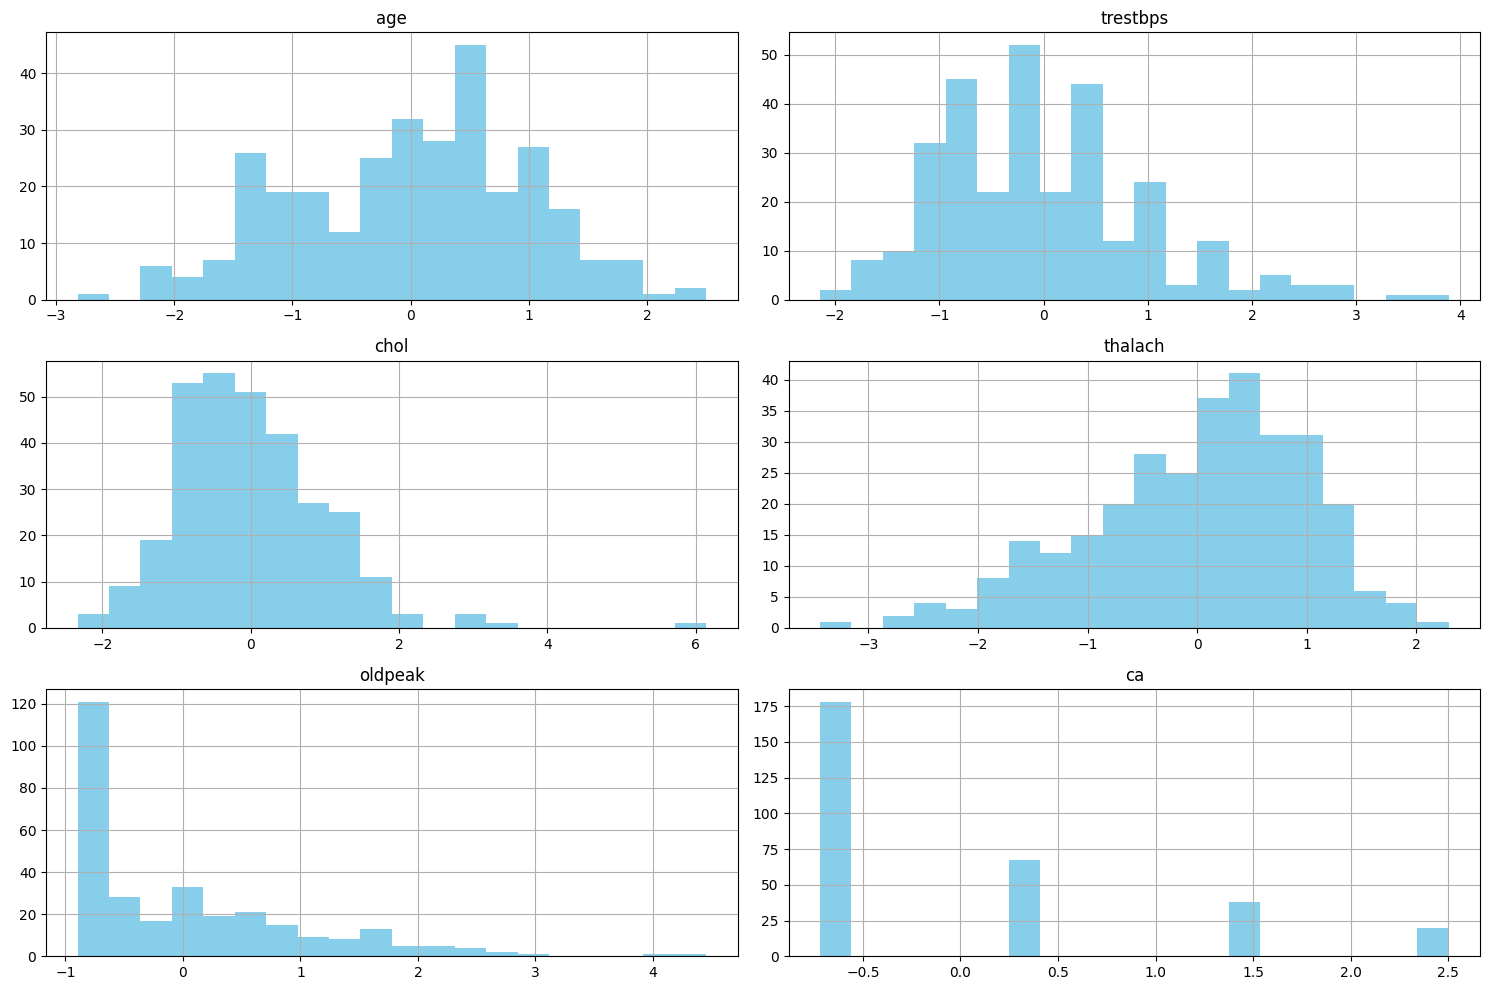

In [181]:
import matplotlib.pyplot as plt

# Plot histograms for all numerical columns
X_encoded[numerical_cols].hist(figsize=(15, 10), bins=20, color='skyblue')
plt.tight_layout()
plt.show()

### Comments on the histograms:
- **age** is well distributed
- **trestbps** is right skewed 
- **chol** seems like it has some outliers as they are far from the other by far (values at 6)
- **thalach** is a little bit left skewed 
- **oldpeak** is right skewed heavily and might have outliers at value 4
- **ca** is categorical and most of the values are concentrated at the lowest value

### Correlation Heatmap

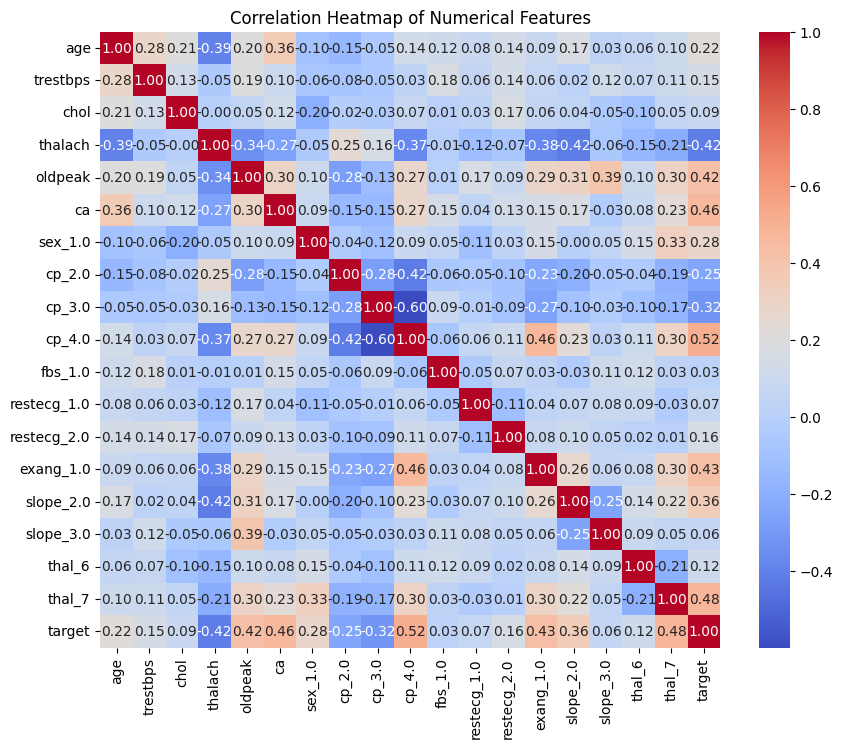

In [182]:
import seaborn as sns

df_corr = X_encoded.copy()
df_corr["target"] = y

# 2. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


### Comments on Correlation Heatmap:
- Correlations with the target variable:
It has the strongest correlations with thalach (-0.42), oldpeak (0.5), ca (0.52), cp_4 (0.49), exang_1 (0.4) and thal_7 (0.47). These features are likely the most important predictors of the target outcome in a linear model.

- There are some multicolinearity between features that hopefully will be solved with PCA in the next step

### Box Plot

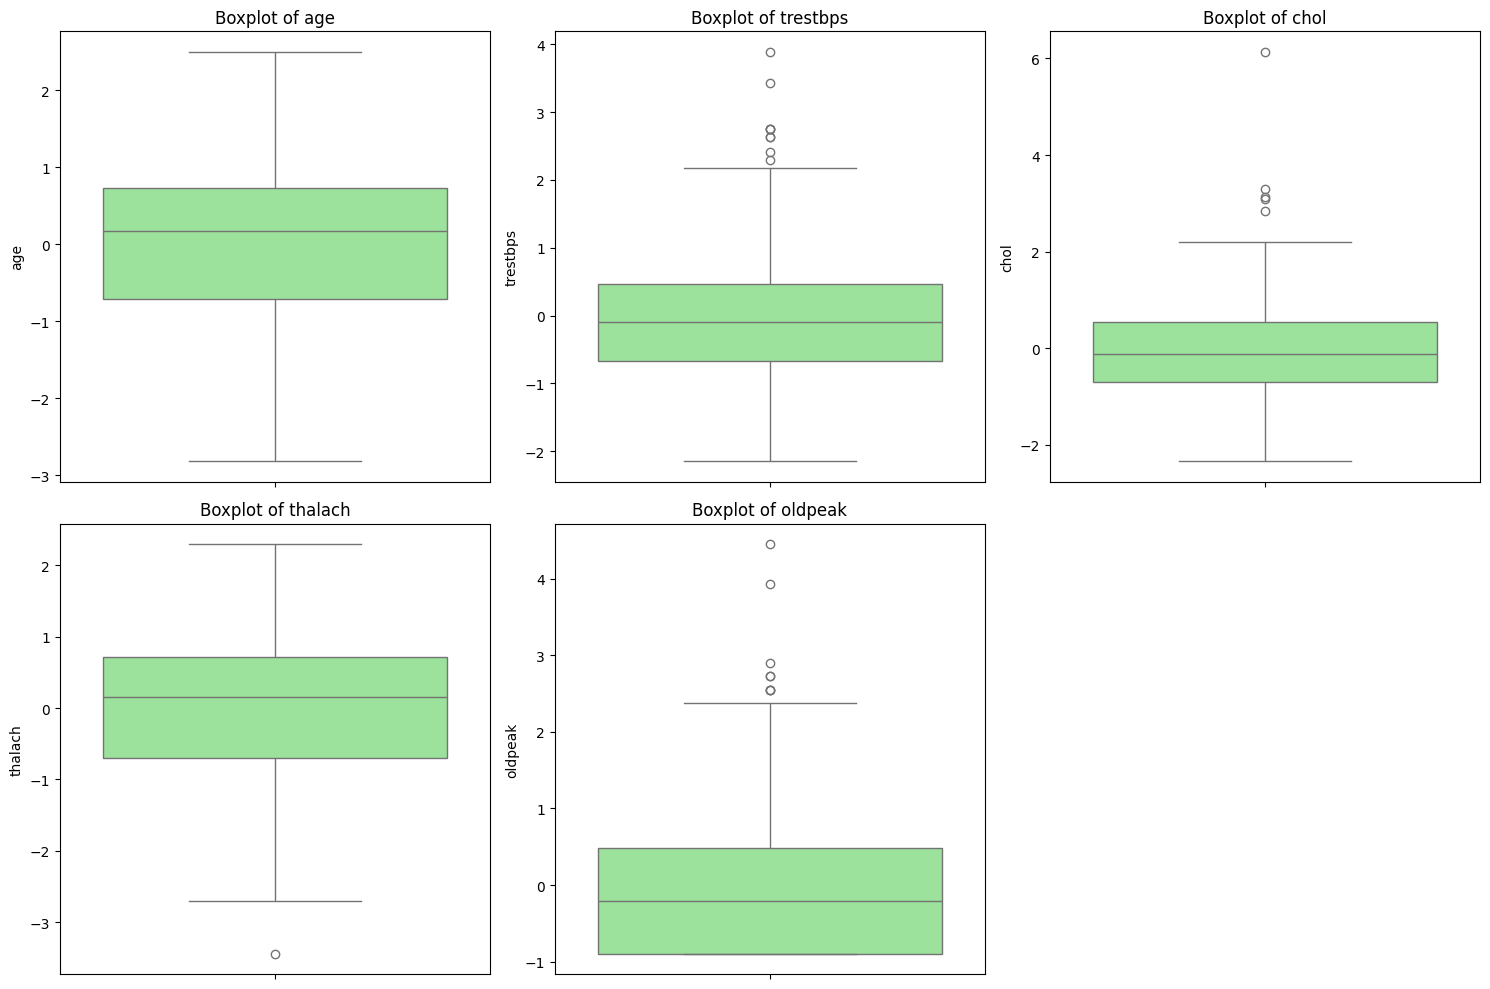

In [183]:
# Boxplots for numerical features
plt.figure(figsize=(15, 10))
numerical_cols.remove('ca')
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols)//3 + 1, 3, i)
    sns.boxplot(y=X_encoded[col], color='lightgreen')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

### Comments on Box Plot:
- it shows lots of outliers in chol (I mentioned in histogram), trestbps, oldpeak, thalach

['ca', 'sex_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'fbs_1.0', 'restecg_1.0', 'restecg_2.0', 'exang_1.0', 'slope_2.0', 'slope_3.0', 'thal_6', 'thal_7']


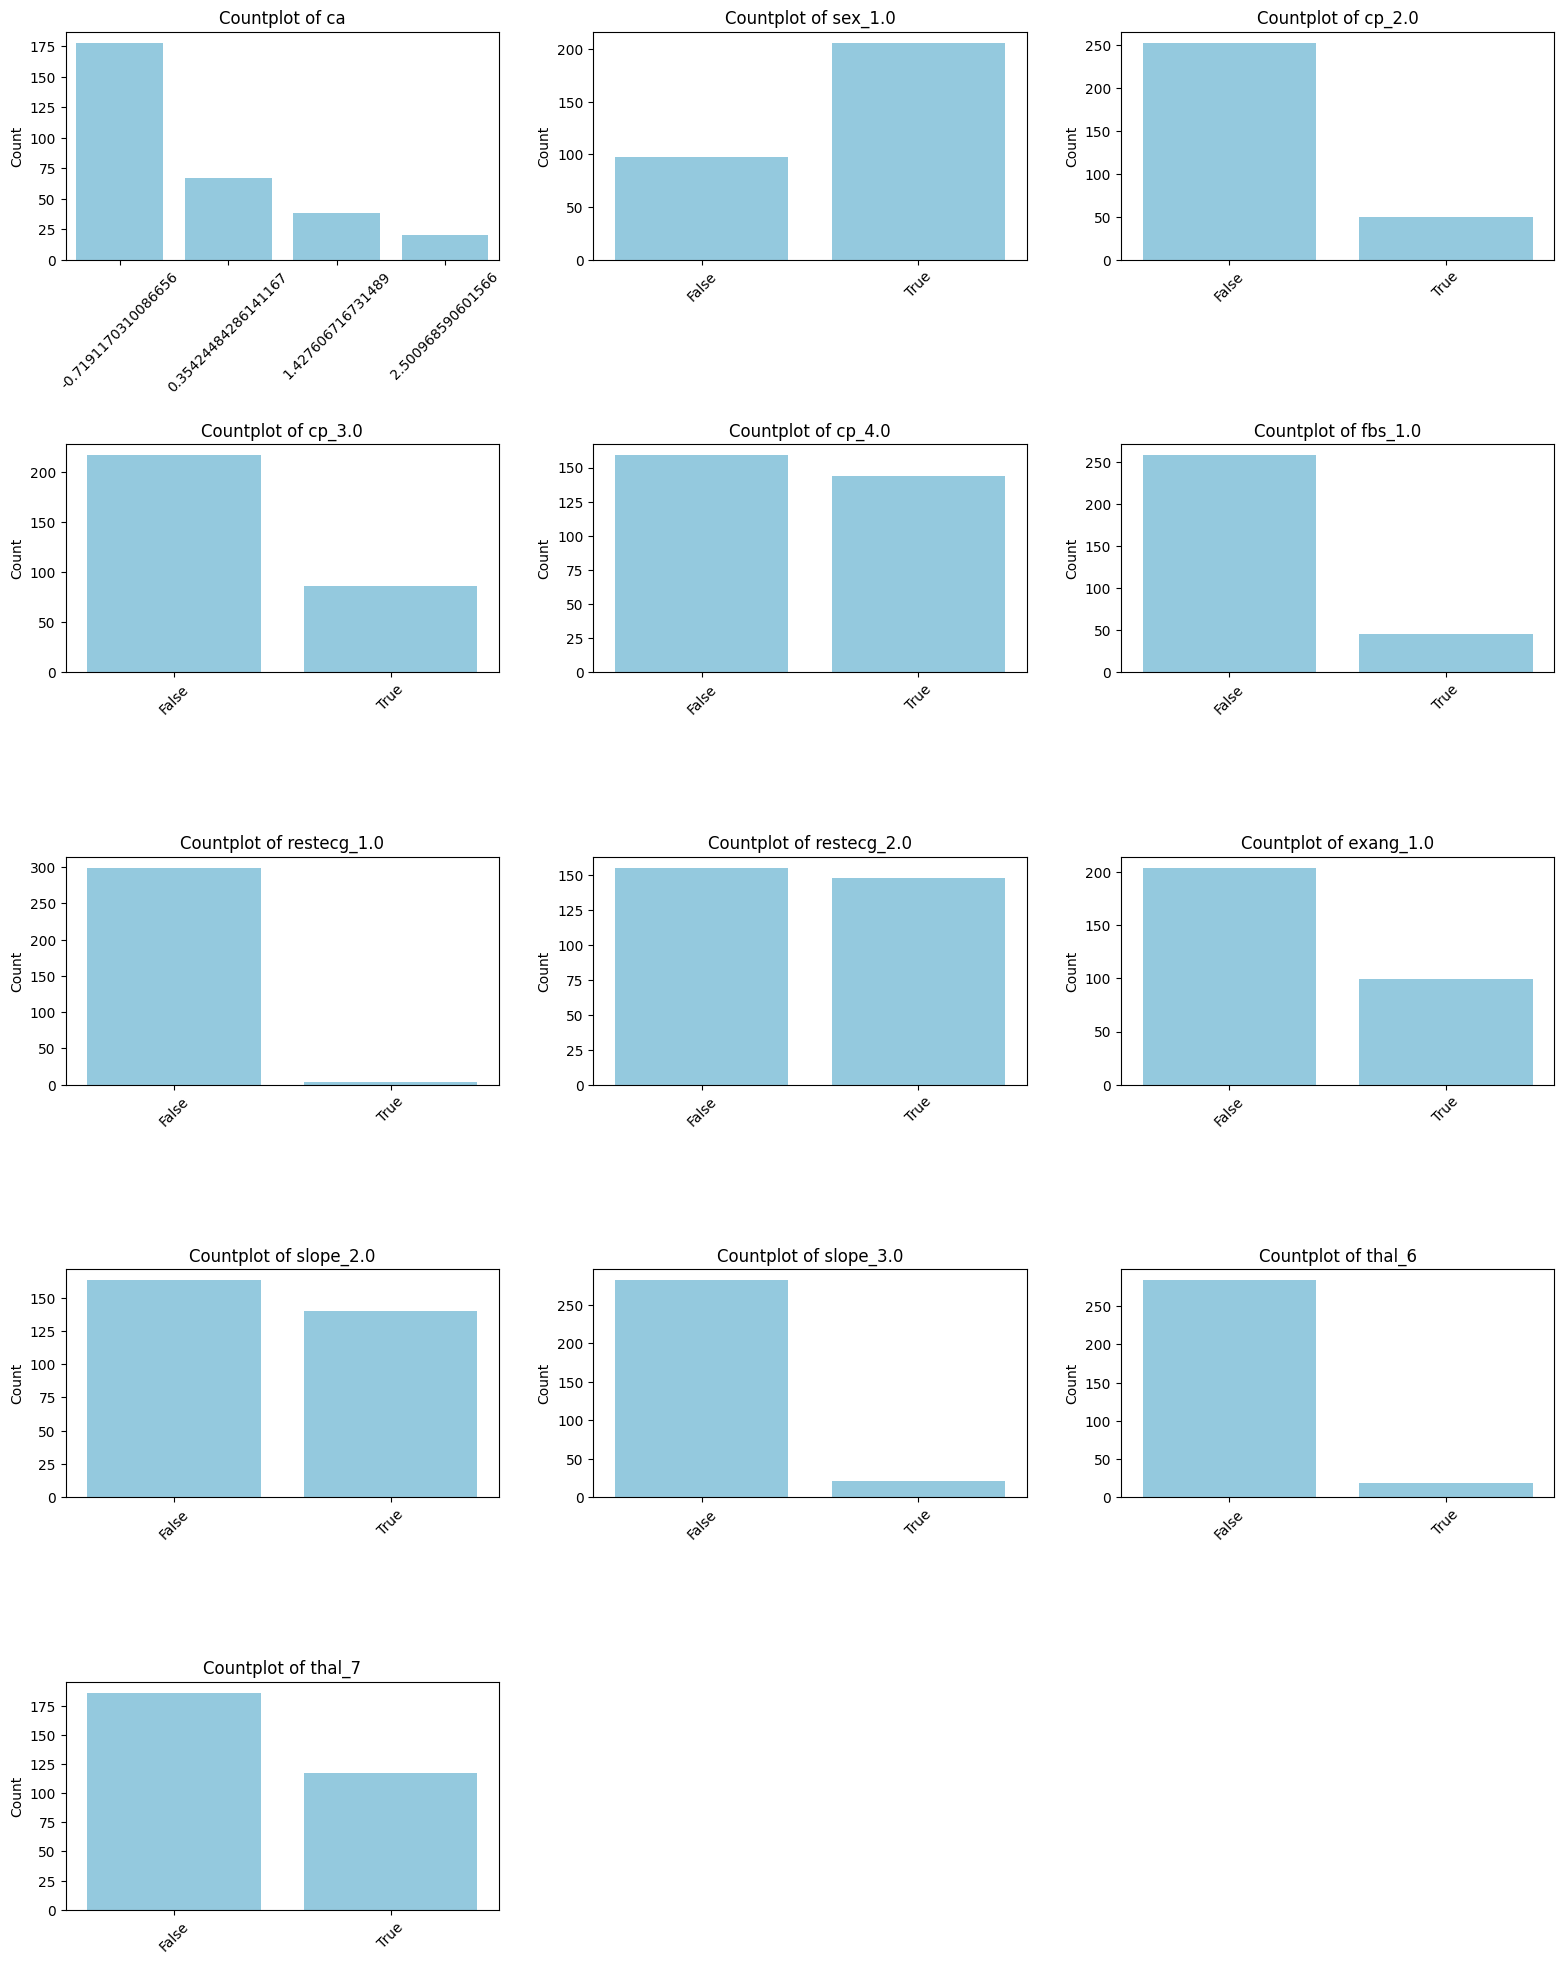

In [184]:
import math

categorical_cols = [col for col in X_encoded.columns if col not in numerical_cols]
print(categorical_cols)


n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)


fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 20))


for ax, col in zip(axes.flatten(), categorical_cols):
    sns.countplot(x=col, data=X_encoded, ax=ax, color="skyblue")
    ax.set_title(f'Countplot of {col}', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('')
    ax.set_ylabel('Count') 

# 4. Hide any unused subplots
for i in range(len(categorical_cols), len(axes.flatten())):
    axes.flatten()[i].set_visible(False)

plt.tight_layout(pad=2.0) 
plt.show()

### Comments on Count Plot:
- ca is mostly of class 0
- sex is biased to one class more than the other
- cp4 is more common than other chest pains
- restecg2 is more common than restecg1
- thal7 is more common than thal6

- it will be more informative if it had target too in each count plot

## Capping Outliers
### capping outliers based on the IQR method

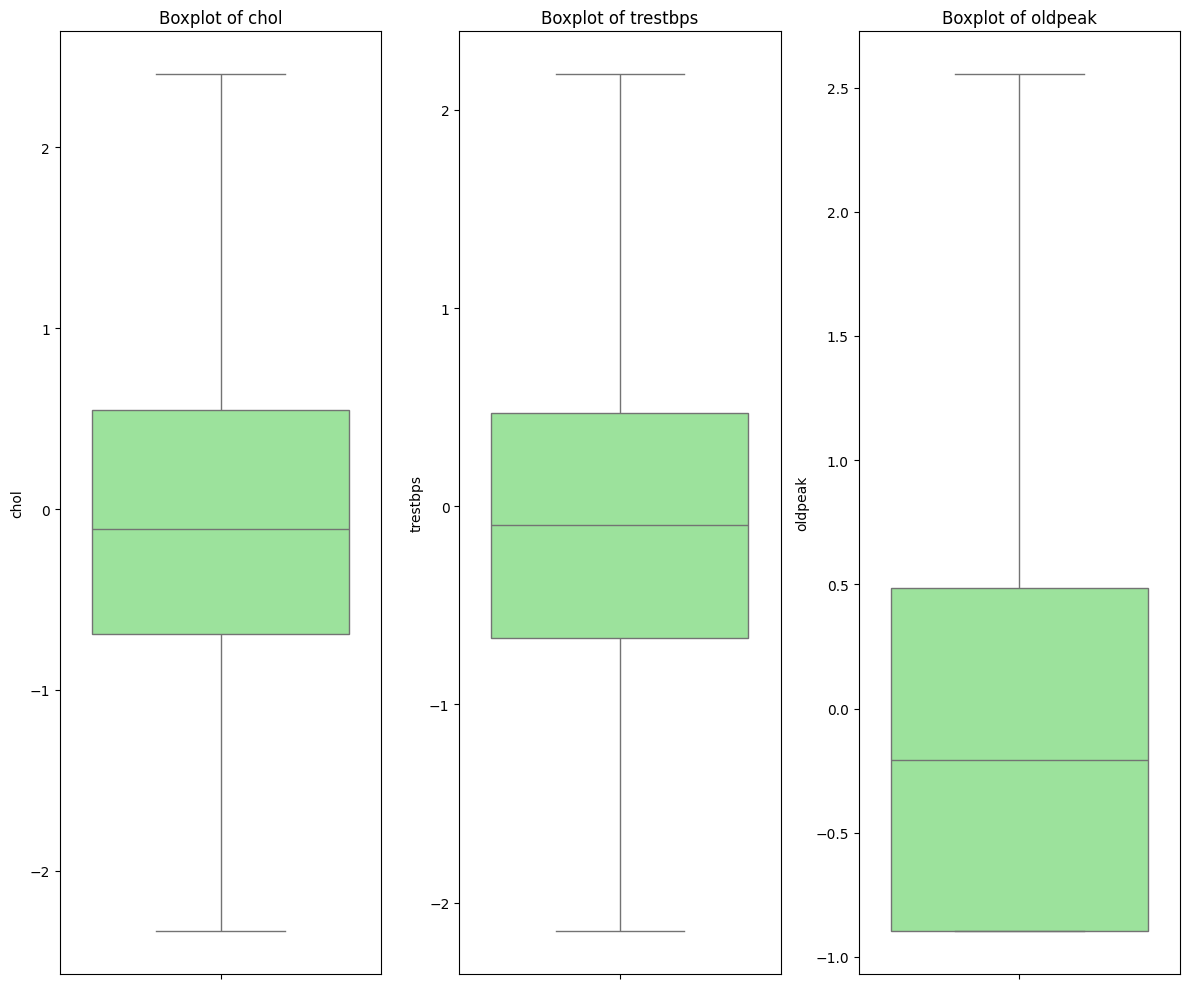

In [ ]:
def cap_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df[column] = df[column].apply(
        lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x
    )
    return df

for col in ['chol', 'trestbps', 'oldpeak']:
    X_cleaned = cap_outliers_iqr(X_encoded, col)

cols_to_plot = ['chol', 'trestbps', 'oldpeak']

plt.figure(figsize=(12, 10))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=X_cleaned[col], color='lightgreen')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()


### Successfully saving the cleaned dataset in heart_disease.csv

In [186]:
import os

# Combine features and target
df_final = pd.concat([X_cleaned, y], axis=1)

df_final = df_final.rename(columns={'num': 'target'})

folder_path = "../data"
file_name = "heart_disease.csv"
full_path = os.path.join(folder_path, file_name)

df_final.to_csv(full_path, index=False)